# Analyze Xenium data

This notebook replaces [squidpy's notebook of the same name](https://squidpy.readthedocs.io/en/stable/notebooks/tutorials/tutorial_xenium.html). It keeps their text and
their calls, and it uses the same Human Lung Cancer sample. It reads the sample from an Arraylake
repository that **holds almost none of the data**. The counts, the images, the segmentation masks
and the transcripts are byte ranges into the files that 10x published. We did not download or
convert any file.

The full list of differences:

- **Loading.** `sd.read_zarr(session.store)` replaces `xenium()` plus `sdata.write()` plus
  `sd.read_zarr(path)`, because the notebook converts nothing. `isd.parquet_in_store()` lets the
  shapes read from the store. The loading cell has no other change. The TIFF parser that wrote the
  image references also supplies their JPEG 2000 codec.
- **Reads.** `isd.repository_config()` retries a dropped connection. `isd.bounded_reads()` limits
  the number of connections that one compute opens. Neither function changes a result.
- **`morphology_focus` has one channel, not four.** 10x publish the other three only inside their
  8 GB `outs.zip`, and they deflate them there. A deflated member is one Huffman-coded stream, so
  no offset inside it is addressable. The channel present is DAPI.
- **The napari cell is present, with the tag `skip-execution`.** It opens a GUI, so a generated
  notebook cannot run it. Run it by hand, after `pip install napari-spatialdata`. This project's
  environment deliberately does not include that package.
- **The two gene figures plot `MET` only.** squidpy's version asks for `["AREG", "MET"]`. `AREG`
  is not in this sample's panel. 10x's own `gene_panel.json` lists 397 targets, and `AREG` is not
  among them. Thus the cells cannot run on the dataset that the notebook says it uses. `MET` and
  `EPCAM` are present.
- **The last `render_shapes` does not pass `use_raw=False`.** `spatialdata-plot` no longer accepts
  it, in the version that squidpy resolves here or in the next version. The rest of that call is
  squidpy's.

Everything else is squidpy's. One more fact is useful, and it is *not* a difference. The store holds
`adata.obsm["spatial"]` and all of `adata.obs` as native data, not as references. They are small,
and the analysis below actually reads them. `X` holds no counts at all, only byte ranges into 10x's
`cell_feature_matrix.h5`. `scanpy` and `squidpy` cannot see the difference.

In [1]:
import warnings

warnings.simplefilter("ignore")

import matplotlib.pyplot as plt
import seaborn as sns

import scanpy as sc
import squidpy as sq
import spatialdata as sd  # noqa: F401

import icechunk_spatialdata as isd

A reader for Xenium data is available in `spatialdata-io`. We use it to parse and convert to Zarr a [Xenium dataset of Human Lung Cancer](https://www.10xgenomics.com/datasets/preview-data-ffpe-human-lung-cancer-with-xenium-multimodal-cell-segmentation-1-standard).

Here that step is already complete, and it copied nothing. The repository below references 10x's
published files directly. It follows the conventions of `spatialdata_io`, so the analysis does not
change.

In [2]:
repo_name = "earthmover-demos/xenium-lung-virtual"

From now on we only read directly from the store.

In [3]:
from arraylake import Client
from arraylake import config as al_config

# The published repo is on prod. A local config can point the client at dev.
al_config.set({"service.uri": "https://api.earthmover.io"})

session = Client().get_repo(repo_name, config=isd.repository_config()).readonly_session("main")
isd.bounded_reads()
with isd.parquet_in_store():
    sdata = sd.read_zarr(session.store)

for kind in ("images", "labels", "shapes", "tables"):
    for name in getattr(sdata, kind):
        print(f"{kind}/{name}")

images/he_image
images/morphology_focus
labels/cell_labels
labels/nucleus_labels
shapes/cell_circles
shapes/cell_boundaries
tables/table


For the analysis we use the `anndata.AnnData` object, which contains the count matrix, cell and gene annotations. It is stored in the `spatialdata.tables` layer.

In [4]:
adata = sdata.tables["table"]
adata

AnnData object with n_obs × n_vars = 162254 × 541
    obs: 'transcript_counts', 'control_probe_counts', 'control_codeword_counts', 'unassigned_codeword_counts', 'deprecated_codeword_counts', 'total_counts', 'cell_area', 'nucleus_area', 'region', 'cell_id'
    var: 'gene_id', 'feature_type'
    uns: 'spatialdata_attrs'
    obsm: 'spatial'
    layers: 'X_csc', None (.X)

In [5]:
adata.obs

,transcript_counts,control_probe_counts,control_codeword_counts,unassigned_codeword_counts,deprecated_codeword_counts,total_counts,cell_area,nucleus_area,region,cell_id
aaaadpbp-1,0,0,0,0,0,0,68.456877,NaN,cell_circles,aaaadpbp-1
aaaaficg-1,19,0,0,0,0,19,49.130002,21.268595,cell_circles,aaaaficg-1
aaabbaka-1,53,0,0,0,0,53,119.618911,74.778753,cell_circles,aaabbaka-1
aaabbjoo-1,29,0,0,0,0,29,94.241097,59.109533,cell_circles,aaabbjoo-1
aaablchg-1,42,0,0,1,0,43,120.341411,52.426408,cell_circles,aaablchg-1
...,...,...,...,...,...,...,...,...,...,...
ojaaphhh-1,3,0,0,0,0,3,26.913126,11.153594,cell_circles,ojaaphhh-1
ojabeldf-1,6,0,0,0,0,6,5.418750,5.418750,cell_circles,ojabeldf-1
ojacfbid-1,0,0,0,0,0,0,6.502500,6.502500,cell_circles,ojacfbid-1
ojacfhhg-1,2,0,0,0,0,2,7.089532,7.089532,cell_circles,ojacfhhg-1


Squidpy looks for cell coordinates in `.obsm["spatial"]`. By using the Xenium reader from `spatialdata-io` this is already automatically set. For more complex data this needs to be set manually, more details can be found in this [spatialdata tutorial on squidpy integration](https://spatialdata.scverse.org/en/latest/tutorials/notebooks/notebooks/examples/squidpy_integration.html).

In [6]:
adata.obsm["spatial"]

array([[ 206.08981323, 1495.89819336],
       [ 201.76582336, 1816.21081543],
       [ 179.02450562, 2167.25390625],
       ...,
       [4463.31298828, 1576.60400391],
       [4619.91552734, 1454.3223877 ],
       [4620.28125   , 1528.10766602]], shape=(162254, 2))

## Calculate quality control metrics

Calculate the quality control metrics on the `anndata.AnnData` using `scanpy.pp.calculate_qc_metrics`.

In [7]:
sc.pp.calculate_qc_metrics(adata, percent_top=(10, 20, 50, 150), inplace=True)

The percentage of control probes and control codewords can be calculated from `adata.obs`

In [8]:
cprobes = (
    adata.obs["control_probe_counts"].sum() / adata.obs["total_counts"].sum() * 100
)
cwords = (
    adata.obs["control_codeword_counts"].sum() / adata.obs["total_counts"].sum() * 100
)
print(f"Negative DNA probe count % : {cprobes}")
print(f"Negative decoding count % : {cwords}")

Negative DNA probe count % : 0.004279288819220082
Negative decoding count % : 0.0018619806312637002


Next we plot the distribution of total transcripts per cell, unique transcripts per cell, area of segmented cells and the ratio of nuclei area to their cells

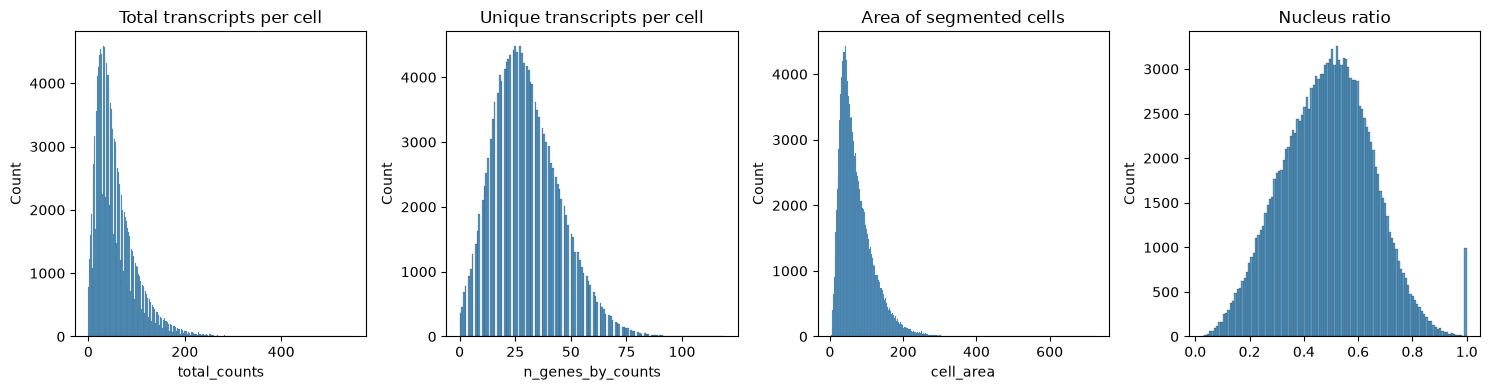

In [9]:
fig, axs = plt.subplots(1, 4, figsize=(15, 4))

axs[0].set_title("Total transcripts per cell")
sns.histplot(
    adata.obs["total_counts"],
    kde=False,
    ax=axs[0],
)

axs[1].set_title("Unique transcripts per cell")
sns.histplot(
    adata.obs["n_genes_by_counts"],
    kde=False,
    ax=axs[1],
)

axs[2].set_title("Area of segmented cells")
sns.histplot(
    adata.obs["cell_area"],
    kde=False,
    ax=axs[2],
)

axs[3].set_title("Nucleus ratio")
sns.histplot(
    adata.obs["nucleus_area"] / adata.obs["cell_area"],
    kde=False,
    ax=axs[3],
)
fig.tight_layout()

Filter the cells based on the minimum number of counts required using `scanpy.pp.filter_cells`. Filter the genes based on the minimum number of cells required with `scanpy.pp.filter_genes`. The parameters for the both were specified based on the plots above.

In [10]:
sc.pp.filter_cells(adata, min_counts=10)
sc.pp.filter_genes(adata, min_cells=5)

Normalize counts per cell using `scanpy.pp.normalize_total`.

Logarithmize, do principal component analysis, compute a neighborhood graph of the observations using `scanpy.pp.log1p`, `scanpy.pp.pca` and `scanpy.pp.neighbors` respectively.

Use `scanpy.tl.umap` to embed the neighborhood graph of the data and cluster the cells into subgroups employing `scanpy.tl.leiden`.

In [11]:
adata.layers["counts"] = adata.X.copy()
sc.pp.normalize_total(adata, inplace=True)
sc.pp.log1p(adata)
sc.pp.pca(adata)
sc.pp.neighbors(adata)
sc.tl.umap(adata)
sc.tl.leiden(adata)

## Visualize annotation on UMAP and spatial coordinates

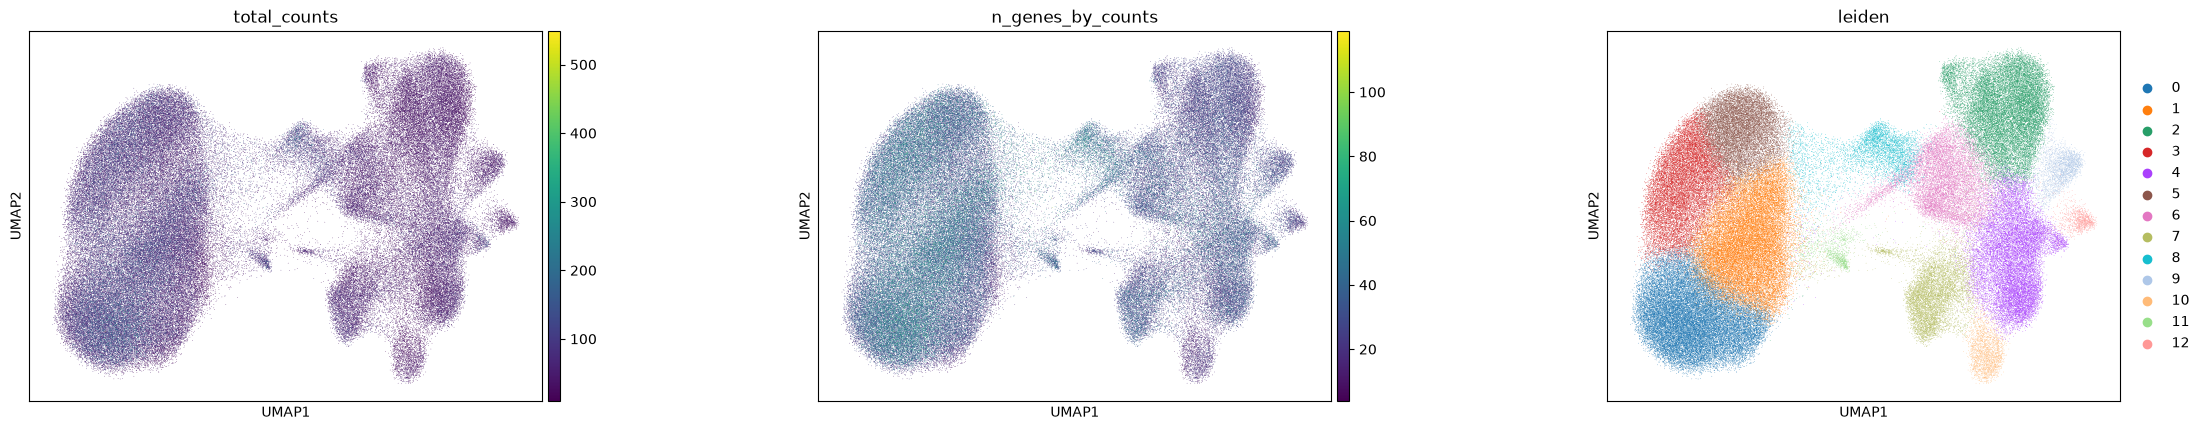

In [12]:
sc.pl.umap(
    adata,
    color=[
        "total_counts",
        "n_genes_by_counts",
        "leiden",
    ],
    wspace=0.4,
)

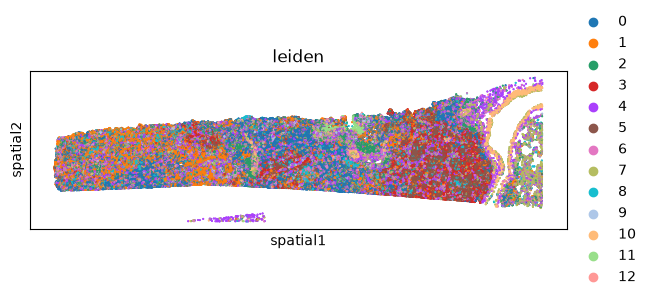

In [13]:
sq.pl.spatial_scatter(
    adata,
    library_id="spatial",
    shape=None,
    color=[
        "leiden",
    ],
    wspace=0.4,
)

## Computation of spatial statistics

This example shows how to compute centrality scores, given a spatial graph and cell type annotation.

The scores calculated are closeness centrality, degree centrality and clustering coefficient with the following properties:

- closeness centrality - measure of how close the group is to other nodes.
- clustering coefficient - measure of the degree to which nodes cluster together.
- degree centrality - fraction of non-group members connected to group members.

All scores are descriptive statistics of the spatial graph.

### Building a spatial neighborhood graph

First, we need to compute a connectivity matrix from spatial coordinates to calculate the centrality scores. We can use `squidpy.gr.spatial_neighbors` for this purpose.

In [14]:
sq.gr.spatial_neighbors(adata, coord_type="generic", delaunay=True)

INFO     Creating graph using `None` transform and `1` libraries.                                                  


### Compute centrality scores

Centrality scores are calculated with `squidpy.gr.centrality_scores`, with the Leiden groups as clusters.

In [15]:
sq.gr.centrality_scores(adata, cluster_key="leiden")

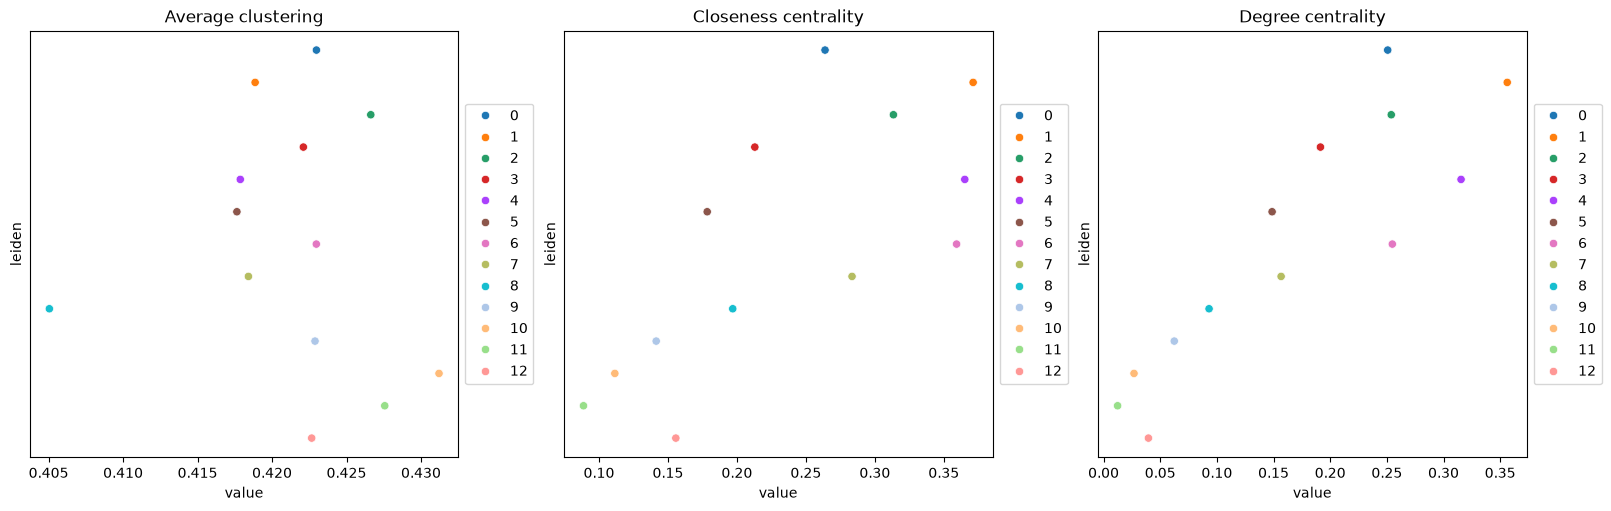

In [16]:
sq.pl.centrality_scores(adata, cluster_key="leiden", figsize=(16, 5))

### Compute co-occurrence probability

This example shows how to compute the co-occurrence probability.

First we create a new table, which is a subset of the original Anndata object, and store it in tables.

In [17]:
sdata.tables["subsample"] = sc.pp.subsample(adata, fraction=0.5, copy=True)
adata_subsample = sdata.tables["subsample"]

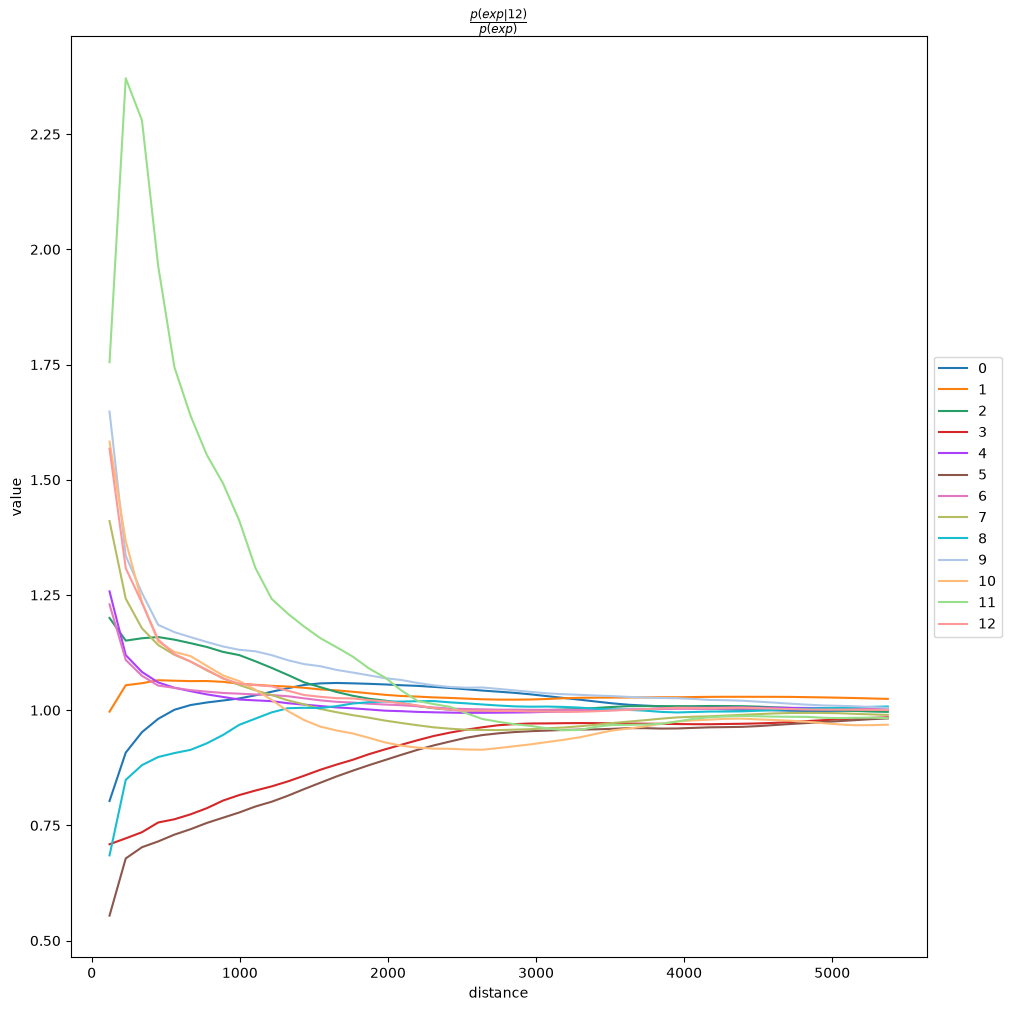

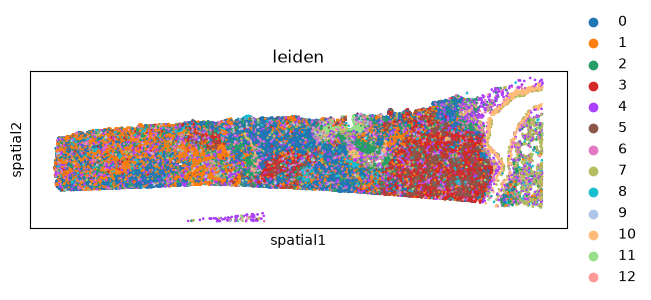

In [18]:
sq.gr.co_occurrence(
    adata_subsample,
    cluster_key="leiden",
)
sq.pl.co_occurrence(
    adata_subsample,
    cluster_key="leiden",
    clusters="12",
    figsize=(10, 10),
)
sq.pl.spatial_scatter(
    adata_subsample,
    color="leiden",
    shape=None,
    size=2,
)

### Neighbors enrichment analysis

It calculates an enrichment score based on proximity on the connectivity graph of cell clusters. The number of observed events is compared against permutations and a z-score is computed.

In [19]:
sq.gr.nhood_enrichment(adata, cluster_key="leiden")

  0%|          | 0/1000 [00:00<?, ?/s]

  0%|          | 1/1000 [00:04<1:08:27,  4.11s/]

  2%|▏         | 18/1000 [00:04<02:45,  5.93/s] 

  4%|▎         | 35/1000 [00:04<01:11, 13.41/s]

  5%|▌         | 50/1000 [00:04<00:43, 21.77/s]

...

 68%|██████▊   | 676/1000 [00:08<00:02, 149.93/s]

 69%|██████▉   | 693/1000 [00:08<00:01, 155.48/s]

 71%|███████   | 709/1000 [00:08<00:01, 151.25/s]

 72%|███████▎  | 725/1000 [00:08<00:01, 153.27/s]

100%|██████████| 1000/1000 [00:09<00:00, 110.84/s]

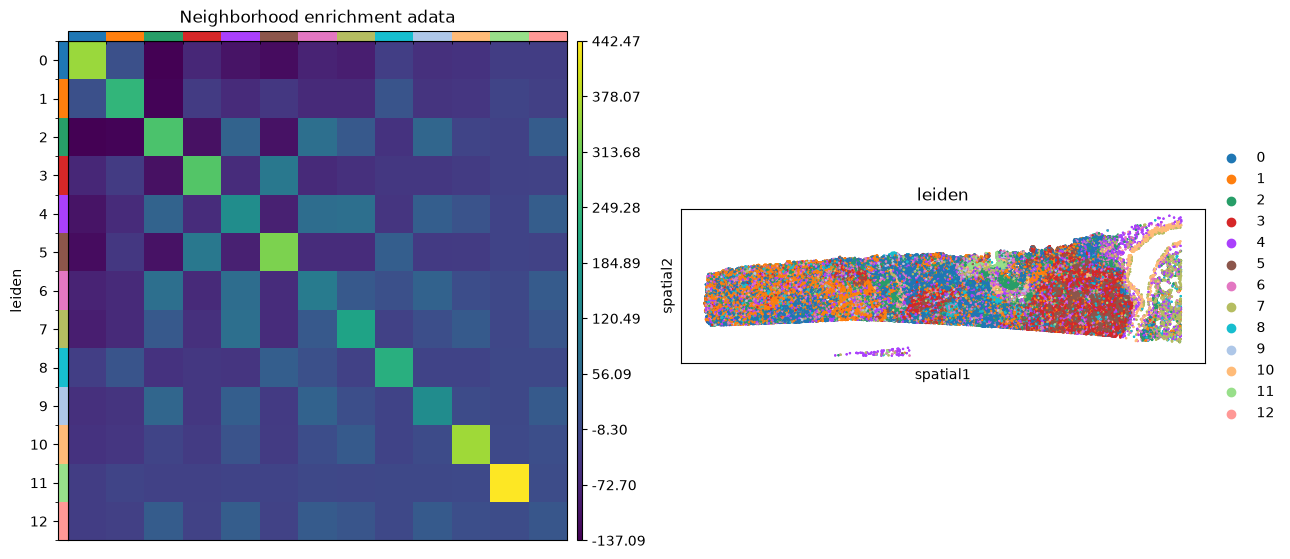

In [20]:
fig, ax = plt.subplots(1, 2, figsize=(13, 7))
sq.pl.nhood_enrichment(
    adata,
    cluster_key="leiden",
    figsize=(8, 8),
    title="Neighborhood enrichment adata",
    ax=ax[0],
)
sq.pl.spatial_scatter(adata_subsample, color="leiden", shape=None, size=2, ax=ax[1])
fig.tight_layout()

### Compute Moran's I score

Identification of spatially variable genes with spatial autocorrelation statistics can be done with
`squidpy.gr.spatial_autocorr`.

We can compute the Moran's I score with `squidpy.gr.spatial_autocorr` and mode = 'moran'. We first
need to compute a spatial graph with `squidpy.gr.spatial_neighbors`. We will also subset the number
of genes to evaluate.

In [21]:
sq.gr.spatial_neighbors(adata_subsample, coord_type="generic", delaunay=True)
sq.gr.spatial_autocorr(
    adata_subsample,
    mode="moran",
    n_perms=100,
    n_jobs=1,
)
adata_subsample.uns["moranI"].head(10)

INFO     Creating graph using `None` transform and `1` libraries.                                                  


  0%|          | 0/100 [00:00<?, ?/s]

  1%|          | 1/100 [00:06<10:53,  6.60s/]

  2%|▏         | 2/100 [00:09<07:31,  4.61s/]

  3%|▎         | 3/100 [00:13<06:25,  3.98s/]

...

 98%|█████████▊| 98/100 [06:33<00:06,  3.42s/]

 99%|█████████▉| 99/100 [06:36<00:03,  3.36s/]

100%|██████████| 100/100 [06:40<00:00,  3.29s/]

100%|██████████| 100/100 [06:40<00:00,  4.00s/]

,I,pval_norm,var_norm,pval_z_sim,pval_sim,var_sim,pval_norm_fdr_bh,pval_z_sim_fdr_bh,pval_sim_fdr_bh
C20orf85,0.580885,0.0,0.000004,0.0,0.009901,0.000008,NaN,NaN,0.013261
CYP2B6,0.559585,0.0,0.000004,0.0,0.009901,0.000007,NaN,NaN,0.013261
MALL,0.495005,0.0,0.000004,0.0,0.009901,0.000006,NaN,NaN,0.013261
C1orf194,0.486236,0.0,0.000004,0.0,0.009901,0.000007,NaN,NaN,0.013261
MYC,0.471065,0.0,0.000004,0.0,0.009901,0.000006,NaN,NaN,0.013261
MS4A1,0.468044,0.0,0.000004,0.0,0.009901,0.000007,NaN,NaN,0.013261
EPCAM,0.430236,0.0,0.000004,0.0,0.009901,0.000007,NaN,NaN,0.013261
CAPN8,0.419548,0.0,0.000004,0.0,0.009901,0.000006,NaN,NaN,0.013261
TCIM,0.391562,0.0,0.000004,0.0,0.009901,0.000006,NaN,NaN,0.013261
MYH11,0.380649,0.0,0.000004,0.0,0.009901,0.000006,NaN,NaN,0.013261


We can visualize some of those genes with `squidpy.pl.spatial_scatter`. We could also pass
`mode = 'geary'` to compute a closely related auto-correlation statistic, Geary's C. See
`squidpy.gr.spatial_autocorr` for more information.

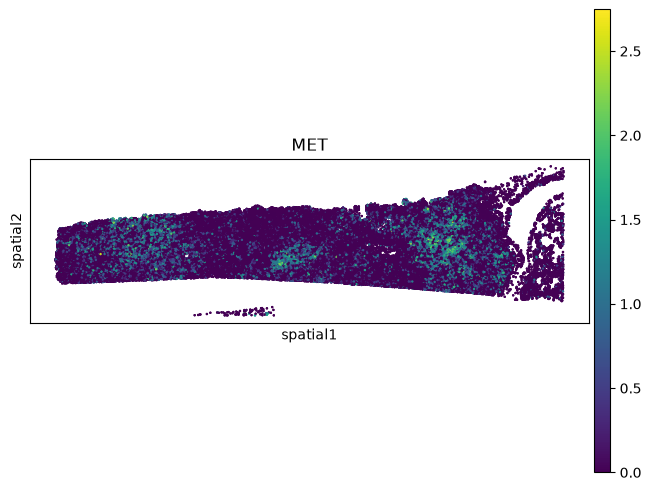

In [22]:
sq.pl.spatial_scatter(
    adata_subsample,
    library_id="spatial",
    color=["MET"],   # squidpy's version also asks for AREG, which this panel does not contain
    shape=None,
    size=2,
    img=False,
)

For plotting we can also use `spatialdata-plot`, a package for static plotting of `spatialdata` objects.

WARNING  render_shapes: Found 7781 NaN values in color data. These observations will be colored with the           
         'na_color'.                                                                                               


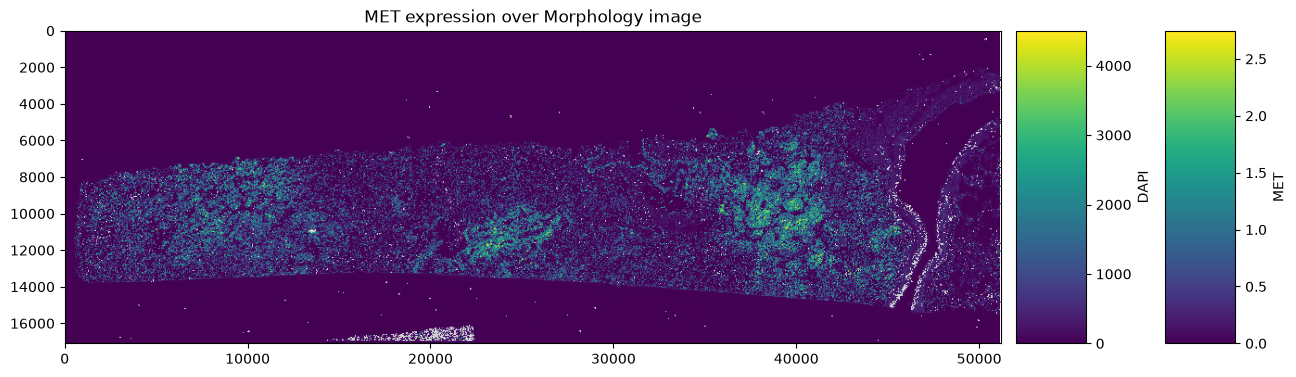

In [23]:
import spatialdata_plot  # noqa: F401

gene_name = ["MET"]   # squidpy's version also asks for AREG, which this panel does not contain
for name in gene_name:
    sdata.pl.render_images("morphology_focus").pl.render_shapes(
        "cell_circles",
        color=name,
        table_name="table",
    ).pl.show(
        title=f"{name} expression over Morphology image",
        coordinate_systems="global",
        figsize=(10, 5),
    )

# Interactive Analysis and Visualization with `napari-spatialdata`

One can leverage `napari-spatialdata` to interactively explore Xenium data through a graphical interface.

The cell below has the tag `skip-execution`. Thus the run that produced this notebook's outputs did
not execute it. The cell opens a Qt window, and a headless run cannot execute that. To get the
viewer, install `napari-spatialdata` and run the cell by hand. This project's environment does not
include napari or its Qt bindings. They are a large dependency for a figure that a headless run
cannot generate anyway.

In [ ]:
from napari_spatialdata import Interactive

Interactive(sdata)

The following demonstrates AREG gene expression visualization across all cells using the interactive viewer:

![title](https://squidpy.readthedocs.io/en/stable/_images/Xenium_tutorial_napari_viewer.png)

That screenshot is squidpy's, not this notebook's. It shows AREG, and this sample's panel does not
contain AREG. The note at the top gives the details. The elements that it lists are the elements
that the store holds.